# Notebook 03: Submission

Memuat pipeline terlatih dari 02_modeling.ipynb, memprediksi test.csv, dan menulis submissions/submission.csv (kolom building_id, damage_grade berupa angka 1–5) siap diunggah ke Kaggle.

Notes: 02_modeling.ipynb sudah dijalankan sehingga models/pipeline_model_lgbm.pkl dan models/cfg3.json ada.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))     # agar paket `scripts` bisa di-import (notebook dijalankan dari notebooks/)

import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from scripts.config import DATA_DIR, MODEL_DIR, SUBMISSION_DIR, FIGURE_DIR
from scripts.predict import predict_grades

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
pipe = joblib.load(MODEL_DIR / 'pipeline_model_lgbm.pkl')     # Pipeline terlatih (fitur -> tipe kategori -> LightGBM)
w = json.load(open(MODEL_DIR / 'cfg3.json'))['w']             # bobot kelas hasil tuning Macro F1
print('bobot kelas:', w)
pipe

bobot kelas: [0.8, 1.2000000000000002, 1.2000000000000002, 1.1, 0.8]


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('encode', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](5,)","[0,1,2,3,4]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['building_id','district_id','vdcmun_id',...,'position', 'plan_configuration','superstructure']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('base', ...), ('location', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that f

1. Dataset

In [3]:
te = pd.read_csv(DATA_DIR / 'test.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
print(te.shape, sample.shape)

(228629, 16) (228629, 2)


2, Prediksi

Probabilitas 5 kelas dikalikan bobot kelas, dipilih kelas terbesar, lalu digeser 0..4 → 1..5.

In [4]:
pred, proba = predict_grades(pipe, te, w)
pred[:10]

array([2, 5, 4, 2, 4, 1, 3, 5, 5, 5])

3. Buat & validasi file submission

In [5]:
sub = pd.DataFrame({'building_id': te['building_id'],        # ID bangunan test
                    'damage_grade': pred})                   # prediksi berupa ANGKA 1-5 (format yang diminta penilai)

# pemeriksaan format sebelum diunggah
assert list(sub.columns) == ['building_id', 'damage_grade']
assert len(sub) == len(sample), 'jumlah baris tidak sama dengan sample_submission'
assert (sub.building_id.values == sample.building_id.values).all(), 'urutan/isi building_id berbeda dari sample_submission'
assert sub.damage_grade.between(1, 5).all() and sub.damage_grade.notna().all()

sub.to_csv(SUBMISSION_DIR / 'submission.csv', index=False)  # file yang diunggah ke Kaggle
print('tersimpan:', SUBMISSION_DIR / 'submission.csv', sub.shape)
sub.head()

tersimpan: C:\Users\HP\Downloads\structural-damage-classification (1)\structural-damage-classification\submissions\submission.csv (228629, 2)


,building_id,damage_grade
0,122207000141,2
1,284909000871,5
2,241904000231,4
3,248308000891,2
4,300405002981,4


4. Sebaran kelas prediksi (cek kewajaran)

Dibandingkan dengan sebaran kelas di data latih (Grade 5 ≈ 36%, Grade 4 ≈ 24%, Grade 3 ≈ 18%, Grade 2 ≈ 11%, Grade 1 ≈ 10%).

damage_grade
1     9.7
2    12.2
3    19.7
4    25.9
5    32.5
Name: proportion, dtype: float64


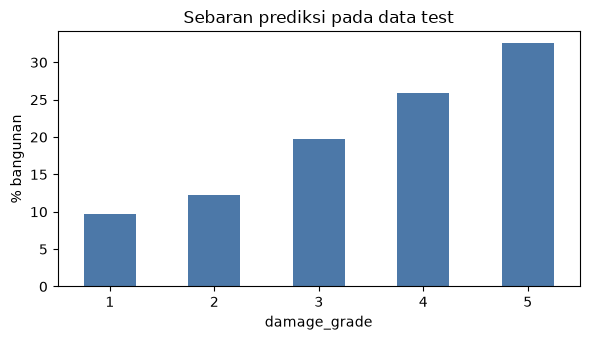

In [6]:
dist = sub.damage_grade.value_counts(normalize=True).sort_index()
print((dist * 100).round(1))
ax = dist.mul(100).plot.bar(color='#4C78A8', figsize=(6, 3.5), rot=0)
ax.set_xlabel('damage_grade'); ax.set_ylabel('% bangunan'); ax.set_title('Sebaran prediksi pada data test')
plt.tight_layout(); plt.savefig(FIGURE_DIR / 'prediction_distribution.png', dpi=130); plt.show()